In [145]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "t2m":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "strd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "ssrd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "rf":   r"C:\greenland\sf_tp_rf.nc",
    "tcc":  r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取夏季 (JJA) 年度均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return summer_mean

def mk_trend_per_decade(y):
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    # ✅ 检查CSV是否已存在（只检查一个，因为两个总是同时生成）
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue
    
    # 打开数据集
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue
    
    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")
    
    # ---- 均值 + MK 趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")
    
    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values
    
    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\\greenland\\1995bu\\fig4")


===== Processing t2m =====
⏭️  t2m 的CSV已存在，跳过

===== Processing strd =====
✅ Summer mean shape: (75, 239, 612)
⏳ Calculating MK trend per grid...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_strd_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_strd_SlidingTrend.csv

===== Processing ssrd =====
⏭️  ssrd 的CSV已存在，跳过

===== Processing rf =====
⏭️  rf 的CSV已存在，跳过

===== Processing tcc =====
⏭️  tcc 的CSV已存在，跳过

✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\greenland\1995bu\fig4


In [2]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "sf":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "tp":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "hcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "lcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "vimdf": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取每年夏季(JJA)均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    da_summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return da_summer_mean

def mk_trend_per_decade(y):
    """对单点时间序列做MK趋势检验"""
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点多年均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    """计算滑动趋势矩阵"""
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue

    # 打开文件
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue

    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")

    # ---- 均值 + MK趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")

    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values

    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\\Users\\greenlandProject\\ERA5LAND\\ProcessFile")



===== Processing sf =====
⏭️  sf 的CSV已存在，跳过

===== Processing tp =====
⏭️  tp 的CSV已存在，跳过

===== Processing hcc =====
⏭️  hcc 的CSV已存在，跳过

===== Processing lcc =====
⏭️  lcc 的CSV已存在，跳过

===== Processing vimdf =====
✅ Summer mean shape: (76, 95, 244)
⏳ Calculating MK trend per grid...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_SlidingTrend.csv

✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\Users\greenlandProject\ERA5LAND\ProcessFile


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression

# ===== 路径 (Path - 请根据你的实际路径修改) =====
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含"albedo"的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 创建 DataFrame 并保存为 CSV =====
# 创建 DataFrame，行索引和列索引都是年份
df = pd.DataFrame(trend_matrix, index=years, columns=years)

# 保存为 CSV 文件
df.to_csv(output_path, index=True, na_rep='')
print(f"✅ CSV file saved to: {output_path}")

# 显示前几行预览
print("\n前5行5列预览:")
print(df.iloc[:5, :5])

ds.close() # 关闭 xarray 数据集


✅ Data range: 1950–2024 (75 years)
✅ CSV file saved to: C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv

前5行5列预览:
      1950  1951      1952      1953      1954
1950   NaN   NaN  0.004835  0.002649  0.002529
1951   NaN   NaN       NaN -0.001646  0.000322
1952   NaN   NaN       NaN       NaN  0.002311
1953   NaN   NaN       NaN       NaN       NaN
1954   NaN   NaN       NaN       NaN       NaN


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")



────────────────────────────────────────────────────────────────────────────────
【文件路径】
────────────────────────────────────────────────────────────────────────────────
C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc

────────────────────────────────────────────────────────────────────────────────
【基本打开（decode_cf=False / True）】
────────────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=False）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'time']
  dims:      {'lat': 237, 'lon': 612, 'time': 75}
  dataset attrs (0):
    (no attrs)

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=True）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'tim

C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:148: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_raw.dims)}")
C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:155: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_cf.dims)}")


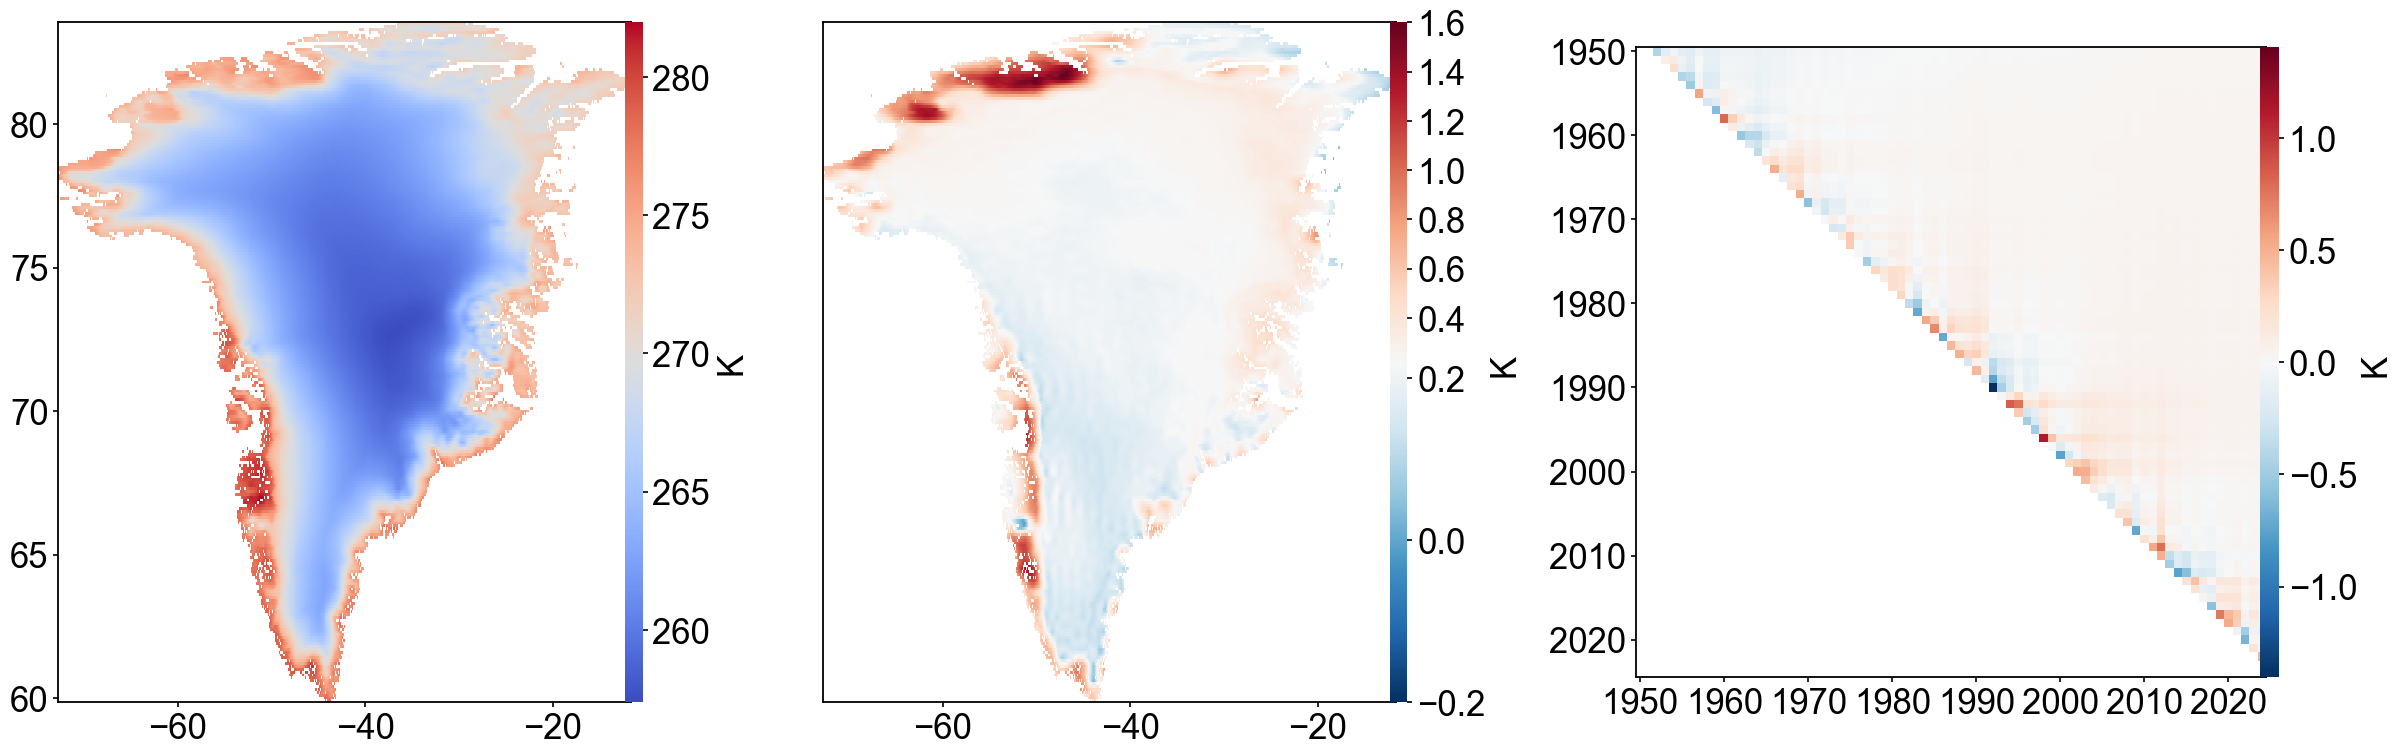

In [5]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_t2m_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_t2m_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 25
CBAR_WIDTH     = "3%"       # 统一colorbar宽度
CBAR_PAD       = 0.02       # colorbar与子图间距
WSPACE_12      = 0.08       # 图1和图2之间的间距
WSPACE_23      = 0.1       # 图2和图3之间的间距
TOP_ALIGN      = 0.95       # 三个子图顶部对齐高度

UNIT_MEAN      = "K"
UNIT_TREND     = "K "
UNIT_SLIDE     = "K "

# 图2的colorbar范围
TREND_VMIN     = -0.2
TREND_VCENTER  = 0.22
TREND_VMAX     = 1.6

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float)
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 图形布局 =====
fig = plt.figure(figsize=(24, 8))

# 手动计算每个子图的位置
left_margin = 0.05
right_margin = 0.97
total_width = right_margin - left_margin

# 三个子图的相对宽度比例
w1_ratio = 1.0
w2_ratio = 1.0
w3_ratio = 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio

# 计算可用于子图的总宽度（减去间距）
total_gap = WSPACE_12 + WSPACE_23
available_width = total_width - total_gap

# 计算每个子图的实际宽度
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)

# 计算每个子图的left位置
left1 = left_margin
left2 = left1 + w1 + WSPACE_12
left3 = left2 + w2 + WSPACE_23

# 创建子图
ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) 夏季均值 ===
im0 = ax0.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax)
cb0.set_label(UNIT_MEAN, fontsize=FONT_SIZE)
cb0.outline.set_visible(False)

# === (2) MK趋势 ===
norm = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
im1 = ax1.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm, shading="auto")

# colorbar紧贴ax1右侧
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax)
cb1.set_label(UNIT_TREND, fontsize=FONT_SIZE)
cb1.outline.set_visible(False)

# 隐藏图2的y轴，只保留图1的纬度
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势热力图 ===
vmax_slide = np.nanmax(np.abs(vals_masked))
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r", norm=norm_slide, shading="auto")
ax2.invert_yaxis()

cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)

# === 样式 ===
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 10))
ax2.set_yticks(np.arange(1950, 2030, 10))
ax2.set_aspect('equal')

plt.show()

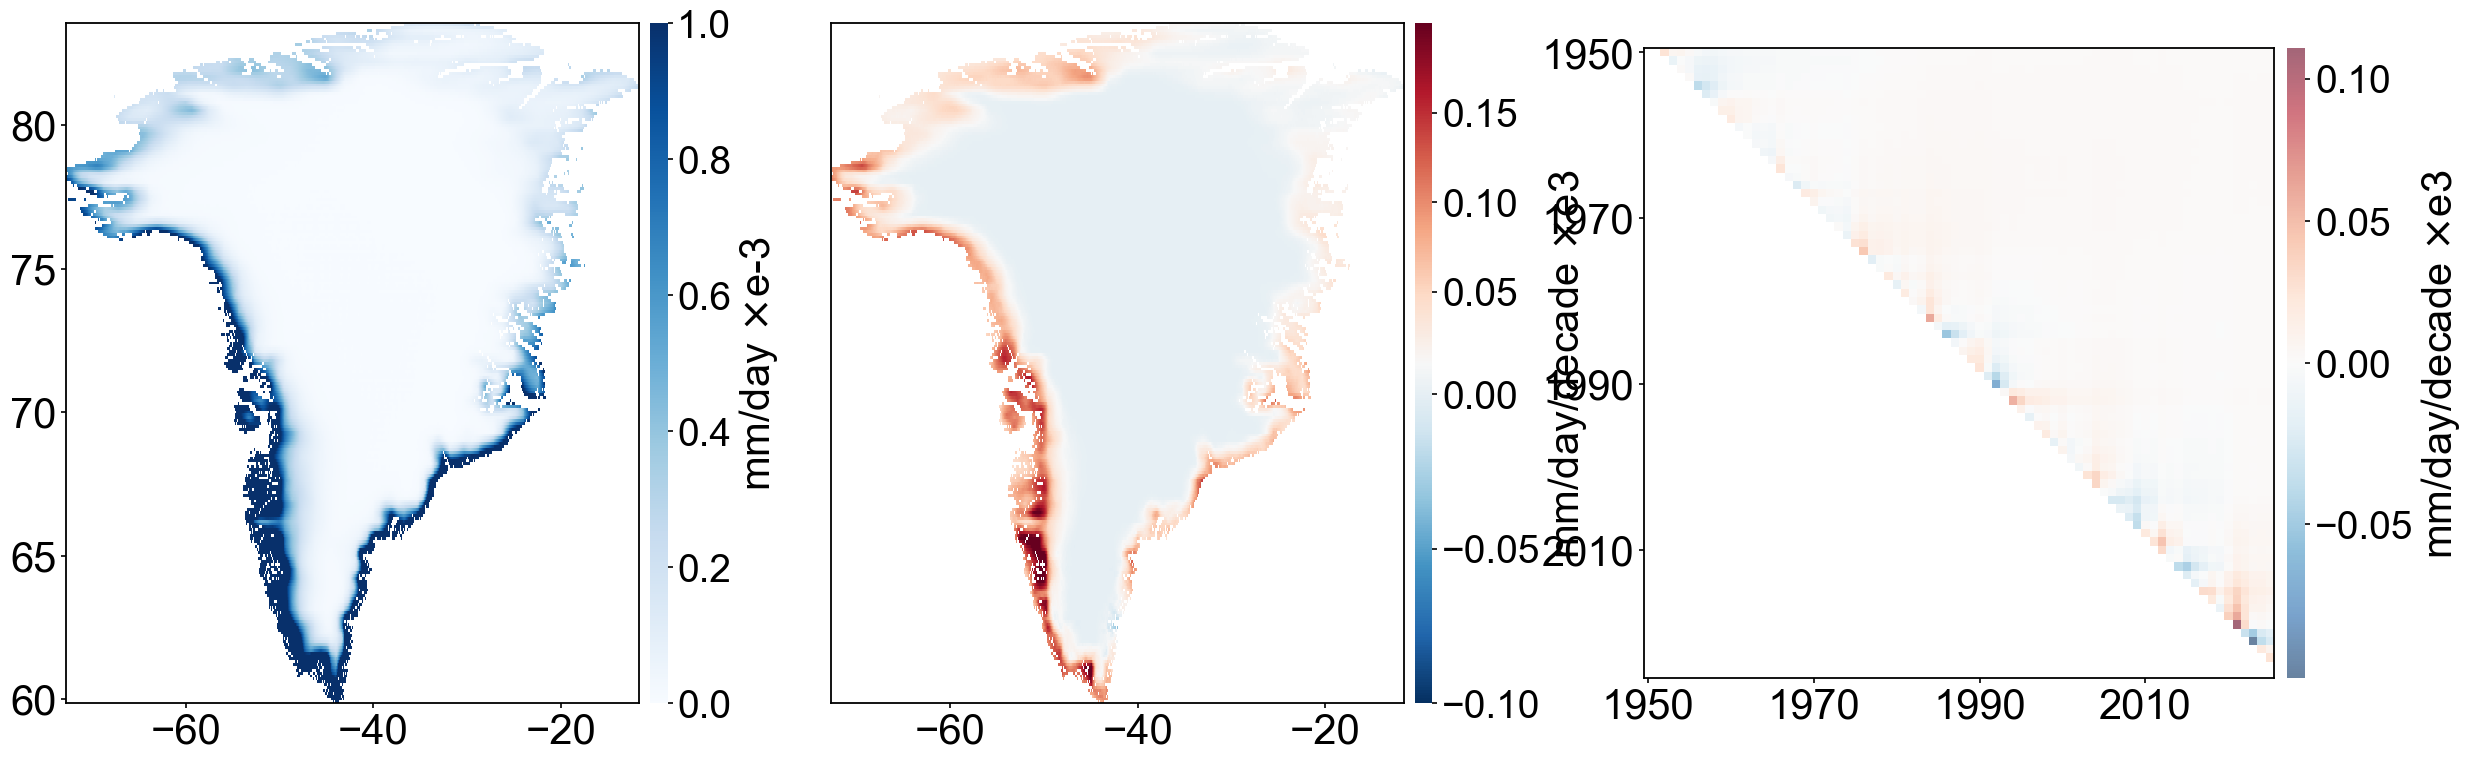

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_rf_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_rf_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 30
CBAR_WIDTH     = "3%"
CBAR_PAD       = 0.05  # 增加colorbar与图的间距，避免遮盖
WSPACE_12      = 0.08
WSPACE_23      = 0.1
TOP_ALIGN      = 0.95

UNIT_MEAN      = r"mm/day $\times$e-3"  # 修改单位
UNIT_TREND     = r"mm/day  $\times$e3"  # 修改单位符号
UNIT_SLIDE     = r"mm/day  $\times$e3"  # 修改单位符号

# ===== 图2趋势中心值参数 =====
TREND_CENTER   = 0.01  # 白色分界线位置

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 缩放（使用全部数据）=====
mean_scaled  = mean_grid.values * 1e3         # 转换为 ×10⁻³ mm/day
trend_scaled = trend_grid.values * 1e3        # 转换为 ×10³ mm/day 

# ===== 设置色带参数 =====
# 图1: 降雨量均值 - 固定范围0到1
MEAN_VMIN = 0.0
MEAN_VMAX = 1.0

# 图2: 趋势 - 固定范围-0.1到0.2
trend_vmin = -0.1
trend_vmax = 0.2

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float) * 1e3   # 同样 ×10³
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# 图3: 滑动趋势 - 使用全部数据范围
slide_vmin = np.nanmin(vals_masked[~mask])
slide_vmax = np.nanmax(vals_masked[~mask])

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 布局 =====
fig = plt.figure(figsize=(24, 8))
left_margin, right_margin = 0.05, 0.97
total_width = right_margin - left_margin
w1_ratio, w2_ratio, w3_ratio = 1.0, 1.0, 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio
total_gap = WSPACE_12 + WSPACE_23
available_width = total_width - total_gap
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)
left1 = left_margin
left2 = left1 + w1 + WSPACE_12
left3 = left2 + w2 + WSPACE_23

# ===== 子图 =====
ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) Mean 降雨量 - 固定刻度0到1 ===
norm_mean = Normalize(vmin=MEAN_VMIN, vmax=MEAN_VMAX)
im0 = ax0.pcolormesh(lons, lats, mean_scaled, cmap="Blues", norm=norm_mean, shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax, ticks=np.arange(0, 1.2, 0.2))
cb0.set_label(f"{UNIT_MEAN}", fontsize=FONT_SIZE)
cb0.outline.set_visible(False)
cb0.ax.tick_params(labelsize=FONT_SIZE-2)

# === (2) 趋势 - 固定刻度-0.1到0.2 ===
norm_trend = TwoSlopeNorm(vmin=trend_vmin, vcenter=TREND_CENTER, vmax=trend_vmax)
im1 = ax1.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r", norm=norm_trend, shading="auto")
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax, ticks=np.arange(-0.1, 0.25, 0.05))
cb1.set_label(f"{UNIT_TREND}", fontsize=FONT_SIZE)
cb1.outline.set_visible(False)
cb1.ax.tick_params(labelsize=FONT_SIZE-2)
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势 - 淡化颜色 ===
import matplotlib.colors as mcolors
cmap_slide = plt.cm.RdBu_r
colors_slide = cmap_slide(np.linspace(0, 1, 256))
colors_slide[:, -1] = 0.6  # 设置alpha为0.6，淡化颜色
cmap_slide_light = mcolors.ListedColormap(colors_slide)

norm_slide = TwoSlopeNorm(vmin=slide_vmin, vcenter=0, vmax=slide_vmax)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light, norm=norm_slide, shading="auto")
ax2.invert_yaxis()
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(f"{UNIT_SLIDE}", fontsize=FONT_SIZE)
cb2.outline.set_visible(False)
cb2.ax.tick_params(labelsize=FONT_SIZE-2)

# ===== 样式 =====
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 20))
ax2.set_yticks(np.arange(1950, 2030, 20))
ax2.set_aspect('equal')

plt.show()

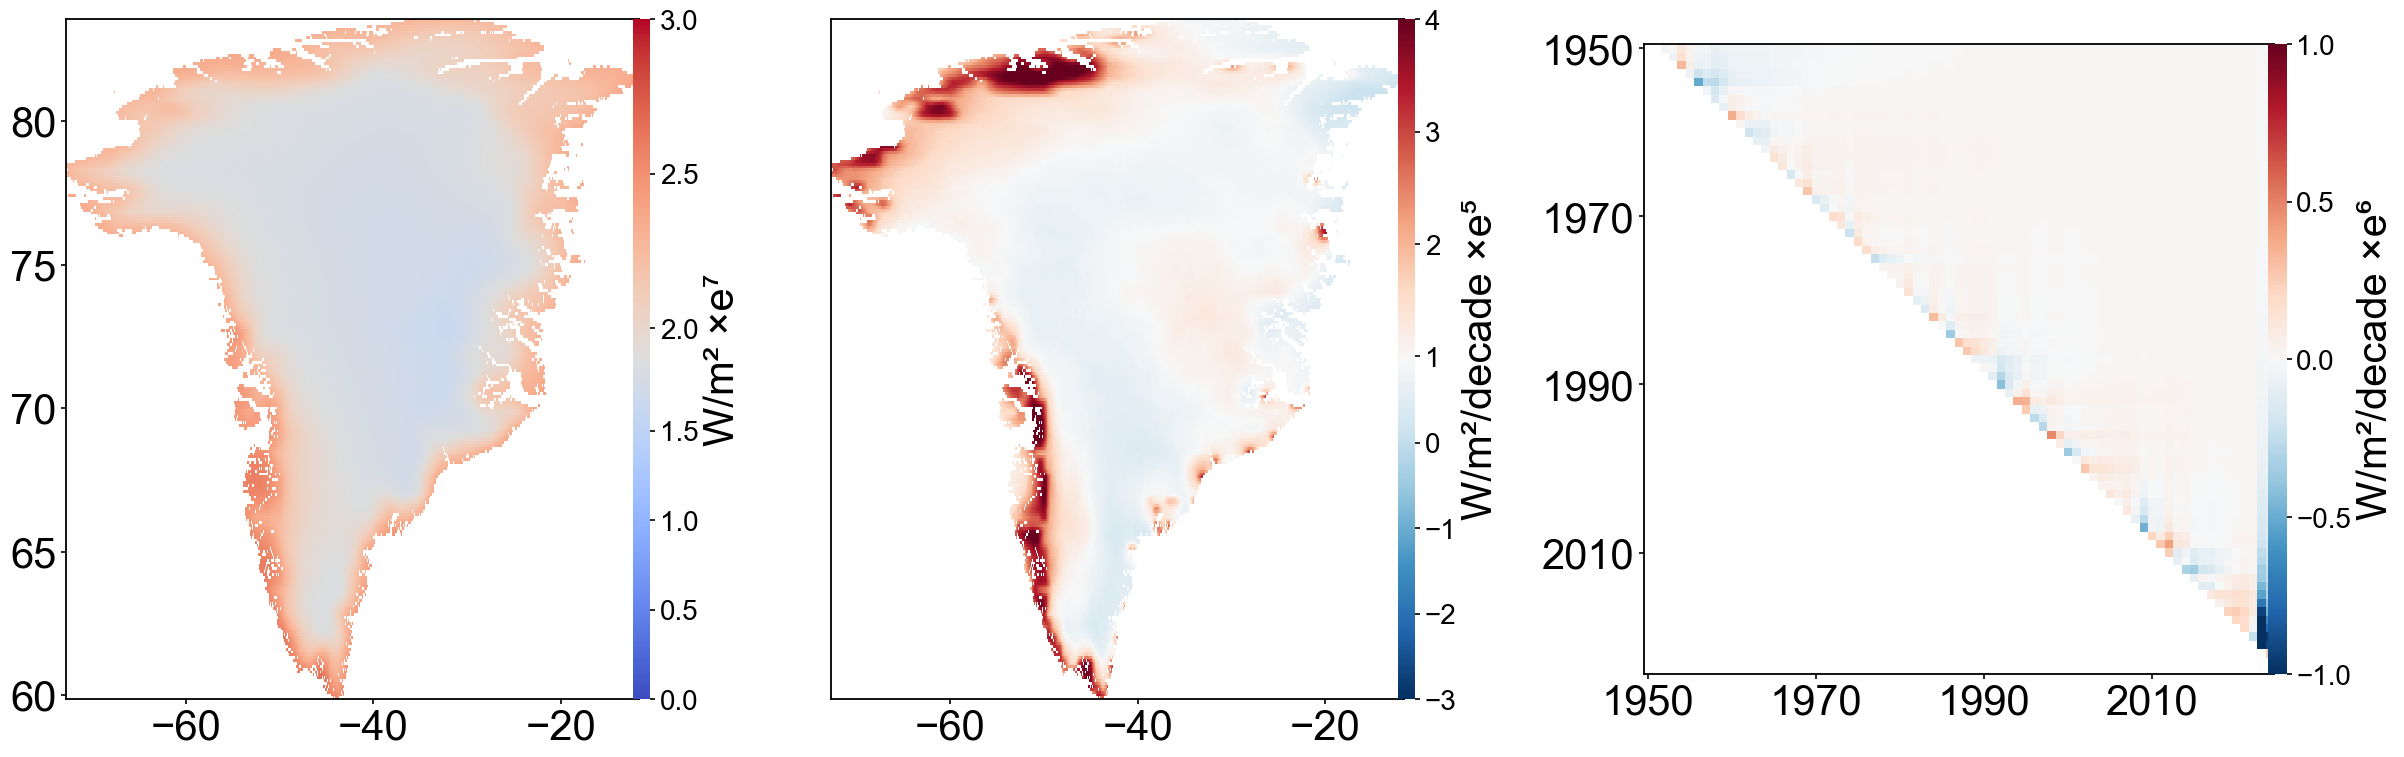

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_strd_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_strd_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 30   # ✅ 改大字体
CBAR_WIDTH     = "3%"
CBAR_PAD       = 0.02
WSPACE_12      = 0.08
WSPACE_23      = 0.1
TOP_ALIGN      = 0.95

# ==== 单位与范围 ====
UNIT_MEAN   = "W/m² ×e⁷"
UNIT_TREND  = "W/m²  ×e⁵"
UNIT_SLIDE  = "W/m²  ×e⁶"   # ✅ 改成 e6

MEAN_VMIN, MEAN_VMAX = 0, 3
TREND_VMIN, TREND_VMAX = -3, 4

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)

# ===== 单位调整（按 e5） =====
trend_grid = trend_grid / 1e5

lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 自动中间值 (保留白色分界) =====
MEAN_VCENTER  = np.nanmedian(mean_grid.values / 1e7)
TREND_VCENTER = np.nanmedian(trend_grid.values)

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float) / 1e6   # ✅ 改成 e6
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 图形布局 =====
fig = plt.figure(figsize=(24, 8))
left_margin, right_margin = 0.05, 0.97
total_width = right_margin - left_margin
total_gap = WSPACE_12 + WSPACE_23

w1_ratio, w2_ratio, w3_ratio = 1.0, 1.0, 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio
available_width = total_width - total_gap
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)
left1, left2, left3 = left_margin, left_margin + w1 + WSPACE_12, left_margin + w1 + WSPACE_12 + w2 + WSPACE_23

ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) 夏季均值 ===
norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
im0 = ax0.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm", norm=norm_mean, shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax)
cb0.set_label(UNIT_MEAN, fontsize=FONT_SIZE)
cb0.outline.set_visible(False)
cb0.set_ticks([0, 0.5,1,1.5, 2,2.5, 3])  # 固定4个刻度

# === (2) 趋势图 ===
norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
im1 = ax1.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm_trend, shading="auto")
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax)
cb1.set_label(UNIT_TREND, fontsize=FONT_SIZE)
cb1.outline.set_visible(False)
cb1.set_ticks([-3, -2, -1, 0, 1, 2, 3, 4])
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势热力图 ===
vmax_slide = 1   # ✅ 改范围 ±1
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r", norm=norm_slide, shading="auto")
ax2.invert_yaxis()
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)
cb2.set_ticks(np.linspace(-1, 1, 5))  # 刻度 -1, -0.5, 0, 0.5, 1

# === 样式统一 ===
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 20))   # ✅ 改为每 20 年
ax2.set_yticks(np.arange(1950, 2030, 20))
ax2.set_aspect('equal')

plt.show()


C:\Users\11823\AppData\Local\Temp\ipykernel_35412\2541842929.py:269: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


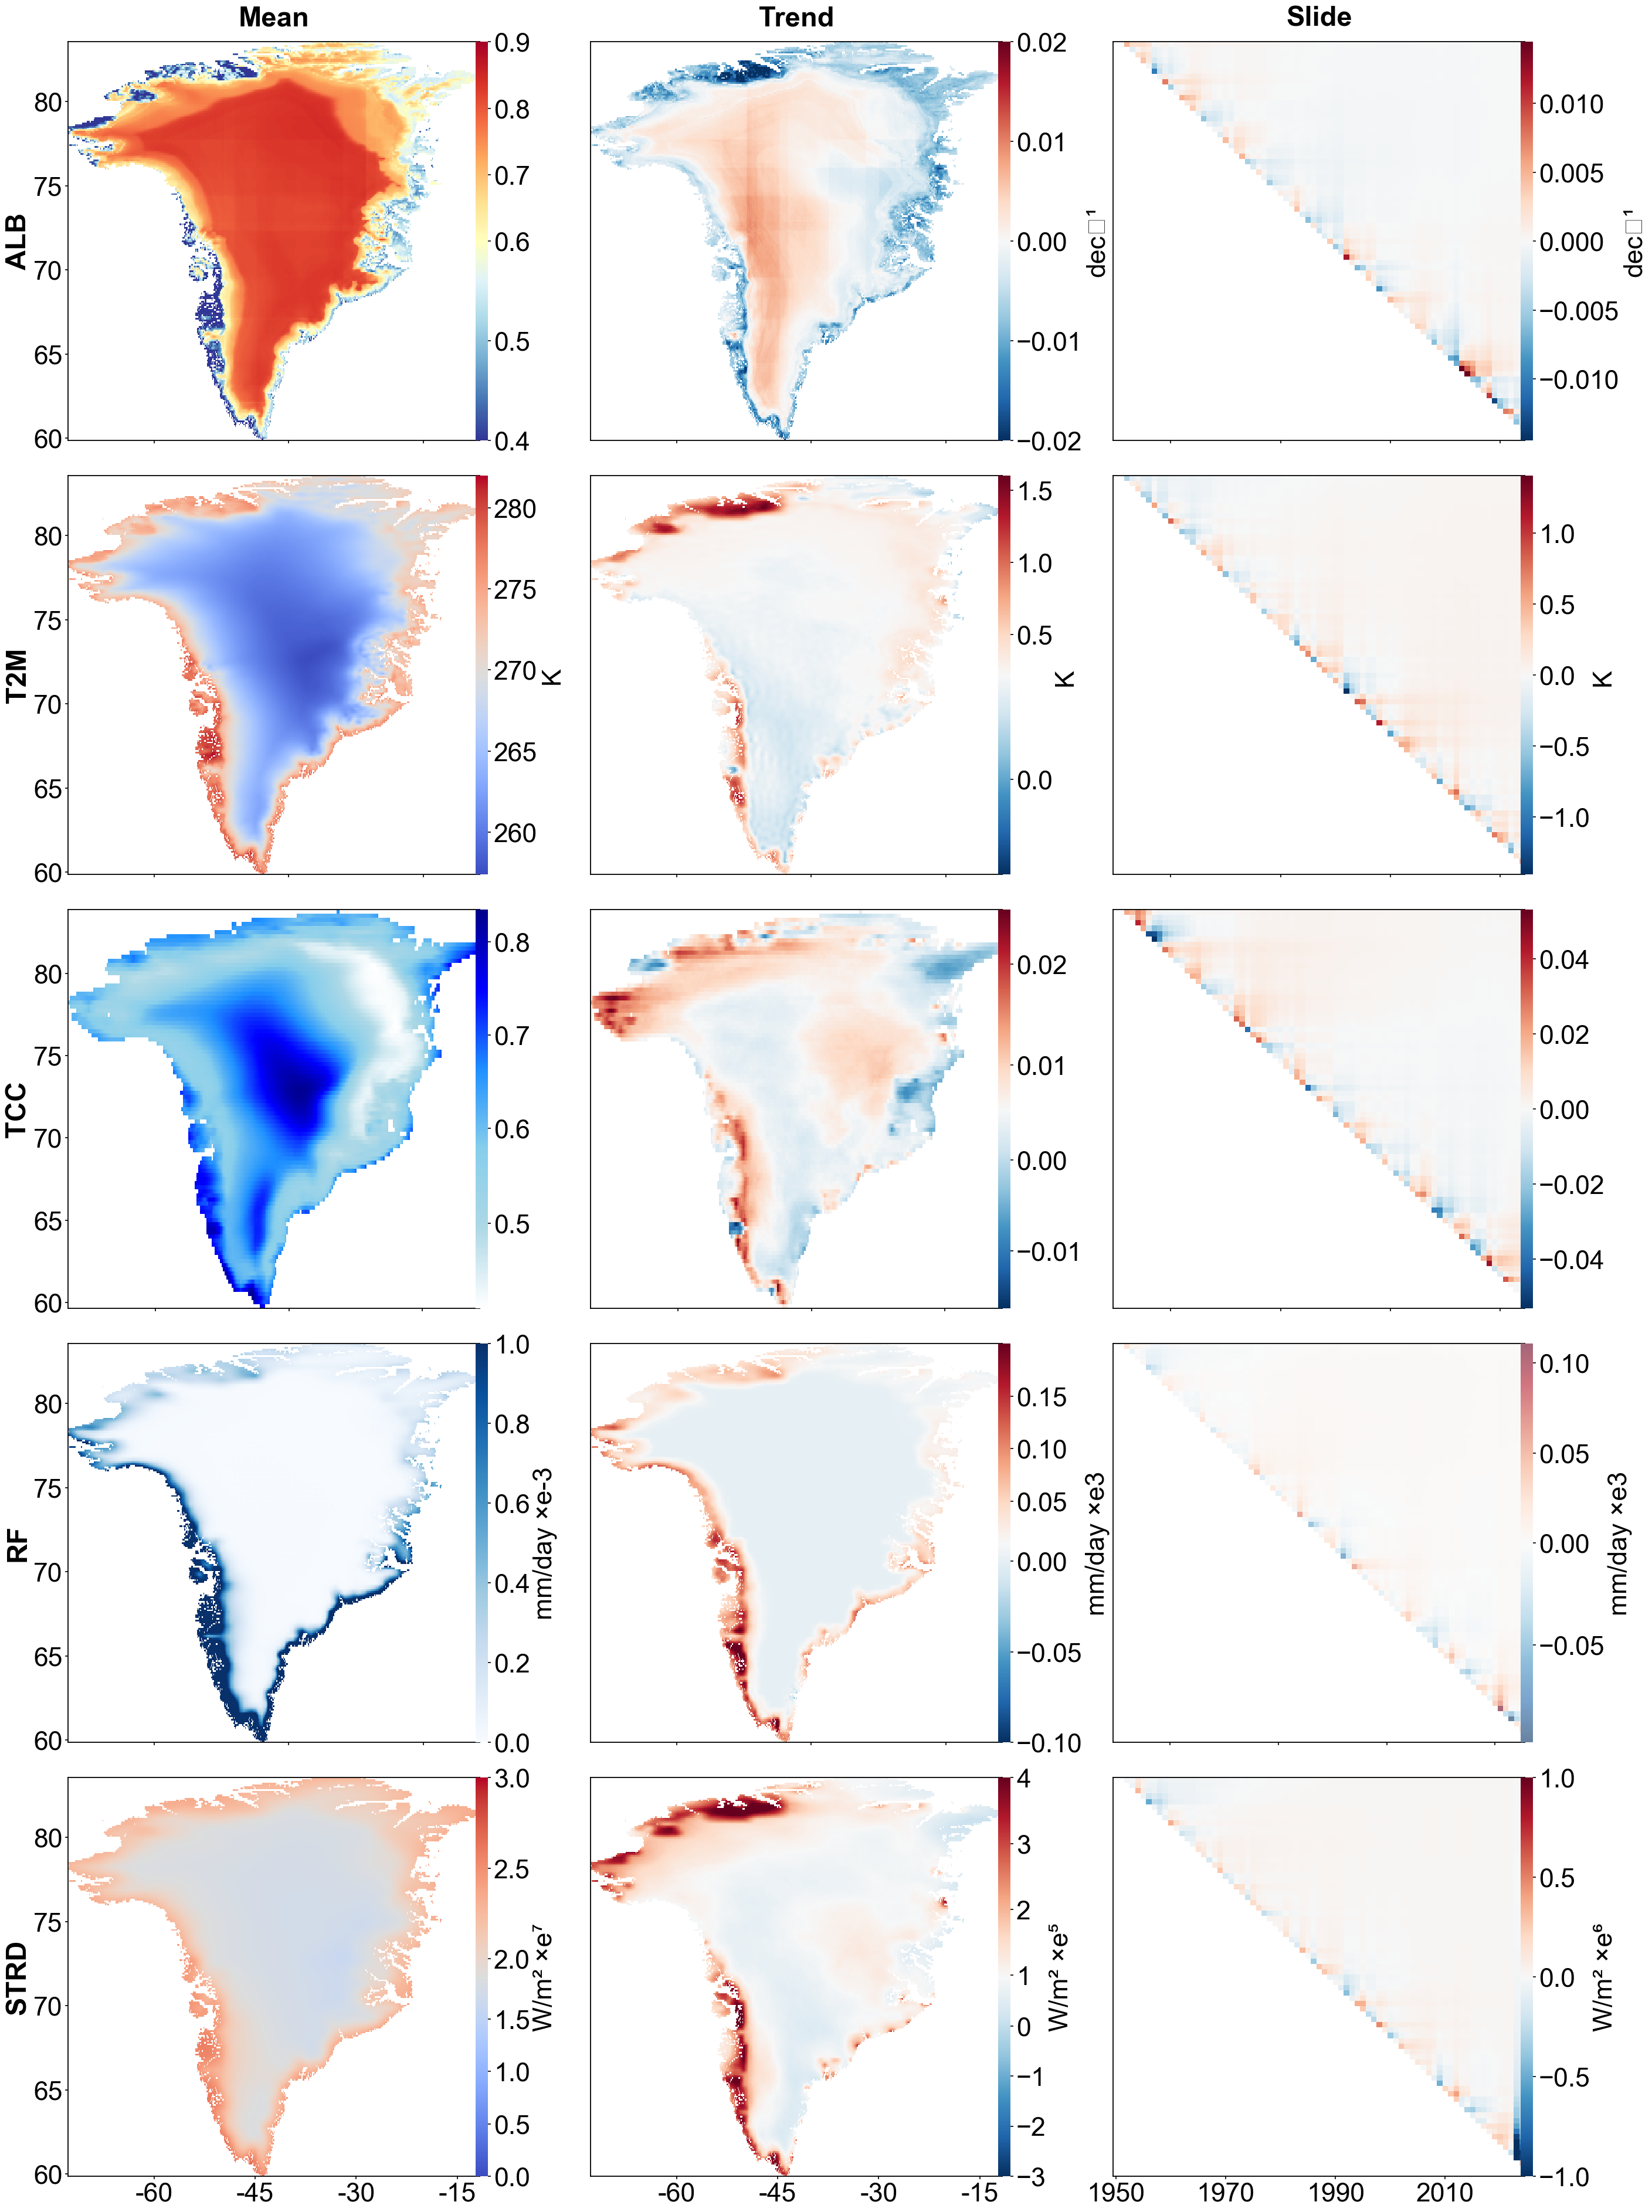

In [1]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel (alb / t2m / tcc / rf / strd)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ===== 参数区 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.07
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig4_5x3panel.png"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

fig = plt.figure(figsize=(27, 40))  # 增高画布
VARS = ["alb", "t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows

axes = []

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        CBAR_WIDTH, CBAR_PAD = "3%", 0.02

        # ================= ALBEDO =================
        if var == "alb":
            meantrend_csv = f"{DATA_DIR}\\Greenland_alb_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_alb_SlidingTrend.csv"

            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            mean_cmap = plt.cm.RdYlBu_r
            trend_cmap = plt.cm.RdBu_r

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values,
                                   cmap=mean_cmap,
                                   norm=TwoSlopeNorm(vmin=0.4, vcenter=0.6, vmax=0.9),
                                   shading="auto")
                label = " "
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values,
                                   cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02),
                                   shading="auto")
                label = "dec⁻¹"
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "dec⁻¹"

        # ================= 其他变量直接复用原逻辑 =================
        elif var == "t2m":
            meantrend_csv = f"{DATA_DIR}\\Greenland_t2m_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_t2m_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
                label = "K"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX),
                                   shading="auto")
                label = "K "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "K "

        elif var == "tcc":
            meantrend_csv = f"{DATA_DIR}\\Greenland_tcc_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_tcc_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            colors_cloud = ['white','lightblue','skyblue','dodgerblue','blue','darkblue']
            cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)
            vcenter_mean = 0.62
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=cmap_cloud,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(mean_grid), vcenter=vcenter_mean, vmax=np.nanmax(mean_grid)),
                                   shading="auto")
                label = ""
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=np.nanmedian(trend_grid), vmax=np.nanmax(trend_grid)),
                                   shading="auto")
                label = " "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = " "

        elif var == "rf":
            meantrend_csv = f"{DATA_DIR}\\Greenland_rf_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_rf_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals = slide.to_numpy(dtype=float) * 1e3
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="Blues",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                label = r"mm/day ×e-3"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.01, vmax=0.2),
                                   shading="auto")
                label = r"mm/day ×e3"
            else:
                cmap_slide = plt.cm.RdBu_r
                colors_slide = cmap_slide(np.linspace(0,1,256)); colors_slide[:,-1]=0.6
                cmap_slide_light = mcolors.ListedColormap(colors_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)),
                                   shading="auto")
                ax.invert_yaxis()
                label = r"mm/day ×e3"

        elif var == "strd":
            meantrend_csv = f"{DATA_DIR}\\Greenland_strd_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_strd_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
            df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
            df = df.dropna(subset=["lat","lon"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid  = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            trend_grid = trend_grid / 1e5
            lats = mean_grid.index.values.astype(float)
            lons = mean_grid.columns.values.astype(float)
            MEAN_VMIN, MEAN_VMAX = 0, 3
            TREND_VMIN, TREND_VMAX = -3, 4
            MEAN_VCENTER  = float(np.nanmedian(mean_grid.values / 1e7))
            TREND_VCENTER = float(np.nanmedian(trend_grid.values))
            eps = 1e-9
            MEAN_VCENTER = np.clip(MEAN_VCENTER, MEAN_VMIN+eps, MEAN_VMAX-eps)
            TREND_VCENTER = np.clip(TREND_VCENTER, TREND_VMIN+eps, TREND_VMAX-eps)
            slide = pd.read_csv(sliding_csv, index_col=0)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float) / 1e6
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm",
                                   norm=norm_mean, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁷"
            elif col == "Trend":
                norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=norm_trend, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁵"
            else:
                vmax_slide = 1.0
                norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=norm_slide, shading="auto")
                ax.invert_yaxis()
                label = "W/m² ×e⁶"

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax)
        cb.set_label(label, fontsize=FONT_SIZE)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=FONT_SIZE)

        # ===== 样式统一 =====
        ax.tick_params(labelsize=FONT_SIZE)
        if i < n_rows - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=20)
        if j == 0:
            ax.text(-0.09, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=FONT_SIZE)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()


✅ Shapefiles loaded: 9 basins | 4 contours


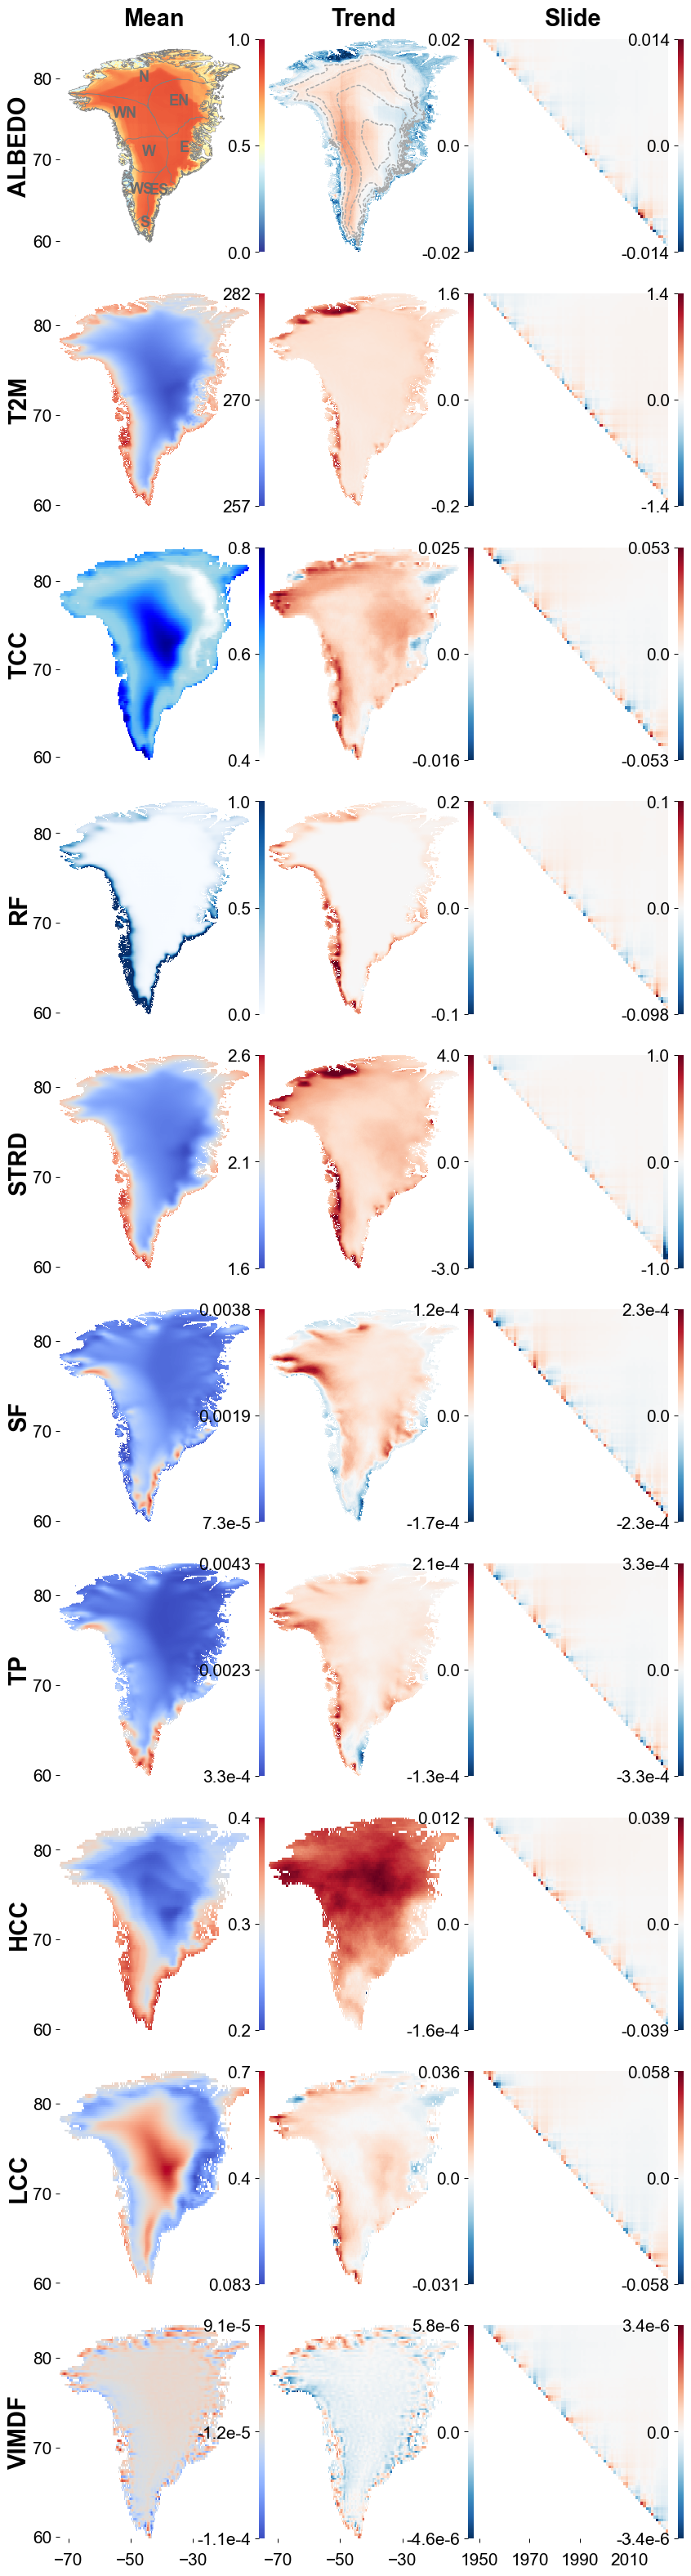

In [13]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel
(ALB fixed aspect ratio, no deformation, thicker contours)

【修改版 v7.1：修复 v7 中的 SyntaxError】
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 19
TICK_FONT_SIZE = FONT_SIZE - 4 # 15
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_10x3panel_final_v7_ticks_refined.png") # (路径保持v7)

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M", "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        gdf["abbr"] = abbr_map.get(os.path.splitext(fname)[0], fname)
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

print(f"✅ Shapefiles loaded: {len(basins_all)} basins | {len(contour_gdf)} contours")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(8.1, 33.6))

VARS = ["albedo", "t2m", "tcc", "rf", "strd",
        "sf", "tp", "hcc", "lcc", "vimdf"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

PAD_TITLE = 12
PAD_XAXIS = 9

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        CBAR_WIDTH, CBAR_PAD = "3%", 0.08 

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)
        
        label = ""

        # ================= ALBEDO =================
        if var == "albedo":
            mean_cmap = plt.cm.RdYlBu_r
            trend_cmap = plt.cm.RdBu_r
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=mean_cmap,
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
                for _, row in basins_all.iterrows():
                    abbr = row["abbr"]
                    if abbr == "M": continue
                    x, y = row.geometry.centroid.x, row.geometry.centroid.y + 0.3
                    ax.text(x, y, abbr, fontsize=FONT_SIZE-6, color="dimgray",
                            ha="center", va="center", fontweight="bold", zorder=6)
                ax.set_aspect('auto', adjustable='box')
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    # ***** 修正点: 修复 SyntaxError *****
                    if isinstance(geom, (LineString, MultiLineString)): # 原为 isinstancegeom,
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for part in parts:
                            xs, ys = part.xy
                            ax.plot(xs, ys, color="darkgrey", linestyle="--",
                                    linewidth=1.0, zorder=5)
                ax.set_aspect('auto', adjustable='box')
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= t2m =================
        elif var == "t2m":
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= tcc =================
        elif var == "tcc":
            colors_cloud = ['white','lightblue','skyblue','dodgerblue','blue','darkblue']
            cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)
            vcenter_mean = 0.62
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=cmap_cloud,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(mean_grid), vcenter=vcenter_mean, vmax=np.nanmax(mean_grid)), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= rf =================
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="Blues",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)), shading="auto")
                ax.invert_yaxis()
        
        # ================= strd =================
        elif var == "strd":
            trend_grid_scaled = trend_grid / 1e5
            vals_masked_scaled = vals_masked / 1e6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=4), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), shading="auto")
                ax.invert_yaxis()

        # ================= (sf, tp, hcc, lcc, vimdf) =================
        else: 
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", 
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # (三点刻度逻辑 保持 v2 修改)
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, 'vcenter'):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.set_label("", fontsize=FONT_SIZE) 
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE) 
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        
        # (刻度格式化 保持 v7 修改)
        formatted_ticks = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 100:
                s = "{:.0f}".format(t)
            elif abs(t) >= 1:
                s = "{:.1f}".format(t)
            elif abs(t) < 0.001: 
                s = "{:.1e}".format(t)
            elif abs(t) < 0.1: 
                s = "{:.2g}".format(t)
            else:
                s = "{:.1f}".format(t)
            
            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted_ticks.append(s)
        cb.set_ticklabels(formatted_ticks)
        
        # ===== 样式 =====
        ax.tick_params(labelsize=TICK_FONT_SIZE) 
        
        if i < n_rows - 1:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)
        else:
            if j < n_cols - 1: 
                ax.set_xticks([-70, -50, -30])
                ax.tick_params(axis='x', pad=PAD_XAXIS)
        
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)
        if j == 0:
            ax.text(-0.15, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=TICK_FONT_SIZE, axis='x', pad=PAD_XAXIS)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

✅ Shapefiles loaded: 9 basins | 4 contours


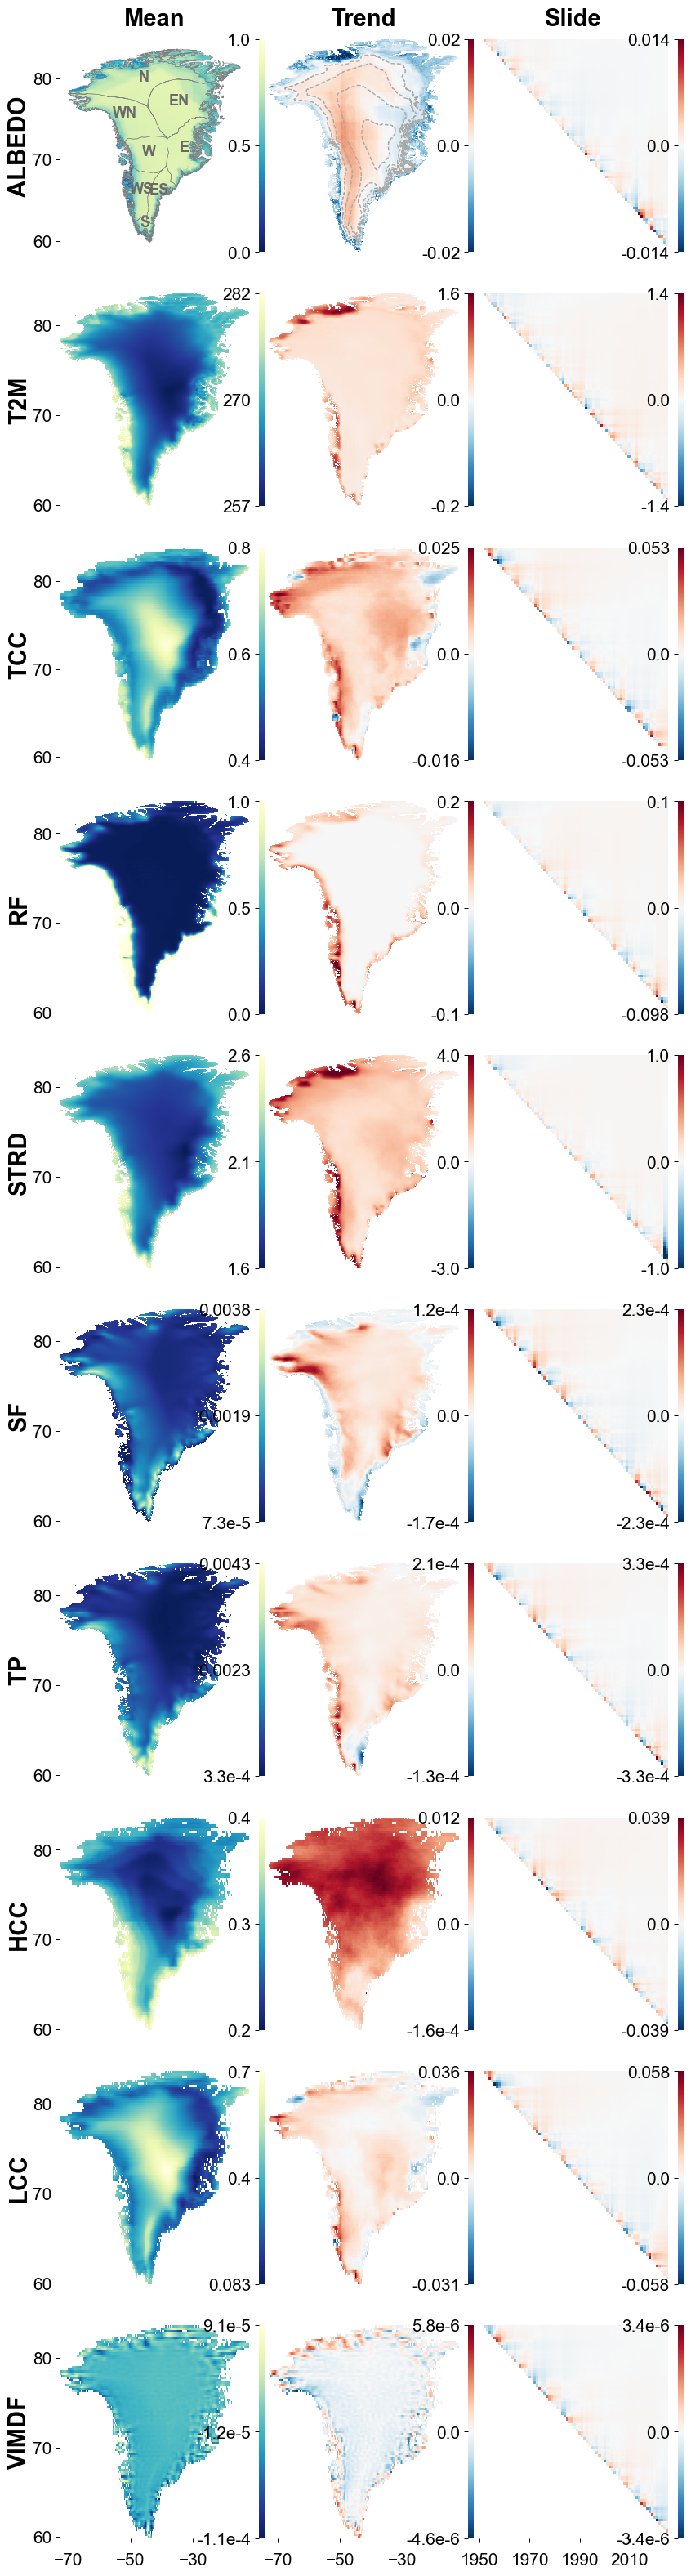

In [8]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel
(ALB fixed aspect ratio, no deformation, thicker contours)

【修改版 v7.3：统一 "Mean" 列配色为 'YlGnBu_r' (亮色代表高值)】
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 19
TICK_FONT_SIZE = FONT_SIZE - 4 # 15
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_10x3panel_final_v7_ticks_refined.png") # (路径保持v7)

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M", "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        gdf["abbr"] = abbr_map.get(os.path.splitext(fname)[0], fname)
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

print(f"✅ Shapefiles loaded: {len(basins_all)} basins | {len(contour_gdf)} contours")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(8.1, 33.6))

VARS = ["albedo", "t2m", "tcc", "rf", "strd",
        "sf", "tp", "hcc", "lcc", "vimdf"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

PAD_TITLE = 12
PAD_XAXIS = 9

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        CBAR_WIDTH, CBAR_PAD = "3%", 0.08 

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)
        
        label = ""

        # ================= ALBEDO =================
        if var == "albedo":
            # [!! 修正 !!] Mean 列统一使用 YlGnBu_r (反向)
            mean_cmap = plt.cm.YlGnBu_r 
            trend_cmap = plt.cm.RdBu_r
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=mean_cmap,
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
                for _, row in basins_all.iterrows():
                    abbr = row["abbr"]
                    if abbr == "M": continue
                    x, y = row.geometry.centroid.x, row.geometry.centroid.y + 0.3
                    ax.text(x, y, abbr, fontsize=FONT_SIZE-6, color="dimgray",
                            ha="center", va="center", fontweight="bold", zorder=6)
                ax.set_aspect('auto', adjustable='box')
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    if isinstance(geom, (LineString, MultiLineString)): 
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for part in parts:
                            xs, ys = part.xy
                            ax.plot(xs, ys, color="darkgrey", linestyle="--",
                                    linewidth=1.0, zorder=5)
                ax.set_aspect('auto', adjustable='box')
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= t2m =================
        elif var == "t2m":
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= tcc =================
        elif var == "tcc":
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= rf =================
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)), shading="auto")
                ax.invert_yaxis()
        
        # ================= strd =================
        elif var == "strd":
            trend_grid_scaled = trend_grid / 1e5
            vals_masked_scaled = vals_masked / 1e6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=4), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), shading="auto")
                ax.invert_yaxis()

        # ================= (sf, tp, hcc, lcc, vimdf) =================
        else: 
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", 
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # (三点刻度逻辑 保持 v2 修改)
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, 'vcenter'):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.set_label("", fontsize=FONT_SIZE) 
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE) 
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        
        # (刻度格式化 保持 v7 修改)
        formatted_ticks = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 100:
                s = "{:.0f}".format(t)
            elif abs(t) >= 1:
                s = "{:.1f}".format(t)
            elif abs(t) < 0.001: 
                s = "{:.1e}".format(t)
            elif abs(t) < 0.1: 
                s = "{:.2g}".format(t)
            else:
                s = "{:.1f}".format(t)
            
            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted_ticks.append(s)
        cb.set_ticklabels(formatted_ticks)
        
        # ===== 样式 =====
        ax.tick_params(labelsize=TICK_FONT_SIZE) 
        
        if i < n_rows - 1:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)
        else:
            if j < n_cols - 1: 
                ax.set_xticks([-70, -50, -30])
                ax.tick_params(axis='x', pad=PAD_XAXIS)
        
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)
        if j == 0:
            ax.text(-0.15, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=TICK_FONT_SIZE, axis='x', pad=PAD_XAXIS)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# -*- coding: utf-8 -*-
"""
计算每个变量 (mean/trend/slide) 的色标范围并四舍五入为三位有效数字
结果打印为对齐表格，可直接用于绘图代码设置 vmin/vmax。
"""

import os
import pandas as pd
import numpy as np

# ======== 输入路径 ========
DIR = r"C:\greenland\1995bu\fig4"

# ======== 要检查的变量（10个） ========
variables = ["albedo", "t2m", "strd", "ssrd", "rf", "tcc", "sf", "tp", "hcc", "lcc", "vimdf"]

# ======== 辅助函数 ========
def format_value(v):
    """保留三位有效数字并自动科学计数法"""
    if np.isnan(v):
        return "NaN"
    if v == 0:
        return "0"
    # 三位有效数字
    s = f"{v:.3g}"
    # 若为0.000等，保留科学记数
    if "e" not in s and abs(v) < 0.001:
        s = f"{v:.3e}"
    return s

def read_range(var):
    """读取三个文件计算上下限"""
    f_mean = os.path.join(DIR, f"Greenland_{var}_MeanTrend.csv")
    f_slide = os.path.join(DIR, f"Greenland_{var}_SlidingTrend.csv")
    if not os.path.exists(f_mean):
        return None
    
    df = pd.read_csv(f_mean)
    mean_vals = df["mean"].values
    trend_vals = df["trend_per_decade"].values

    mean_min, mean_max = np.nanmin(mean_vals), np.nanmax(mean_vals)
    trend_min, trend_max = np.nanmin(trend_vals), np.nanmax(trend_vals)

    slide_min = slide_max = np.nan
    if os.path.exists(f_slide):
        df_slide = pd.read_csv(f_slide, index_col=0)
        vals = df_slide.values
        slide_min, slide_max = np.nanmin(vals), np.nanmax(vals)

    return (mean_min, mean_max, trend_min, trend_max, slide_min, slide_max)

# ======== 主程序 ========
print(f"\n{'变量':<8}{'Mean_min':>14}{'Mean_max':>14}{'Trend_min':>14}{'Trend_max':>14}{'Slide_min':>14}{'Slide_max':>14}")
print("="*90)

for var in variables:
    ranges = read_range(var)
    if ranges is None:
        print(f"{var:<8} 文件缺失，跳过")
        continue

    mean_min, mean_max, trend_min, trend_max, slide_min, slide_max = ranges
    print(f"{var:<8}{format_value(mean_min):>14}{format_value(mean_max):>14}"
          f"{format_value(trend_min):>14}{format_value(trend_max):>14}"
          f"{format_value(slide_min):>14}{format_value(slide_max):>14}")

print("\n✅ 已输出全部变量的色标范围（均保留三位有效数字）。")
print("⚙️ 可直接用于设置每个三联图的 vmin/vmax，例如：vmin=-0.02, vmax=0.02 等。")



变量            Mean_min      Mean_max     Trend_min     Trend_max     Slide_min     Slide_max
albedo           0.205         0.846       -0.0268       0.00974       -0.0132        0.0145
t2m                257           282       -0.0121          1.59          -1.4          1.13
strd          1.63e+07      2.65e+07      8.09e+03      4.62e+05     -4.83e+06      4.78e+05
ssrd          1.61e+07      2.69e+07     -1.24e+06      6.38e+04     -6.81e+06      6.45e+05
rf             2.2e-06       0.00381     -3.51e-05     2.318e-04      -9.8e-05     1.108e-04
tcc               0.41         0.835       -0.0164        0.0254       -0.0531        0.0456
sf            7.26e-05        0.0038    -1.672e-04     1.183e-04    -2.282e-04     2.149e-04
tp           3.310e-04       0.00435    -1.293e-04     2.067e-04    -3.187e-04     3.256e-04
hcc              0.179         0.392    -1.617e-04        0.0121       -0.0389        0.0283
lcc             0.0829         0.733       -0.0311        0.0361     

✅ Colorbar config loaded: 13 entries


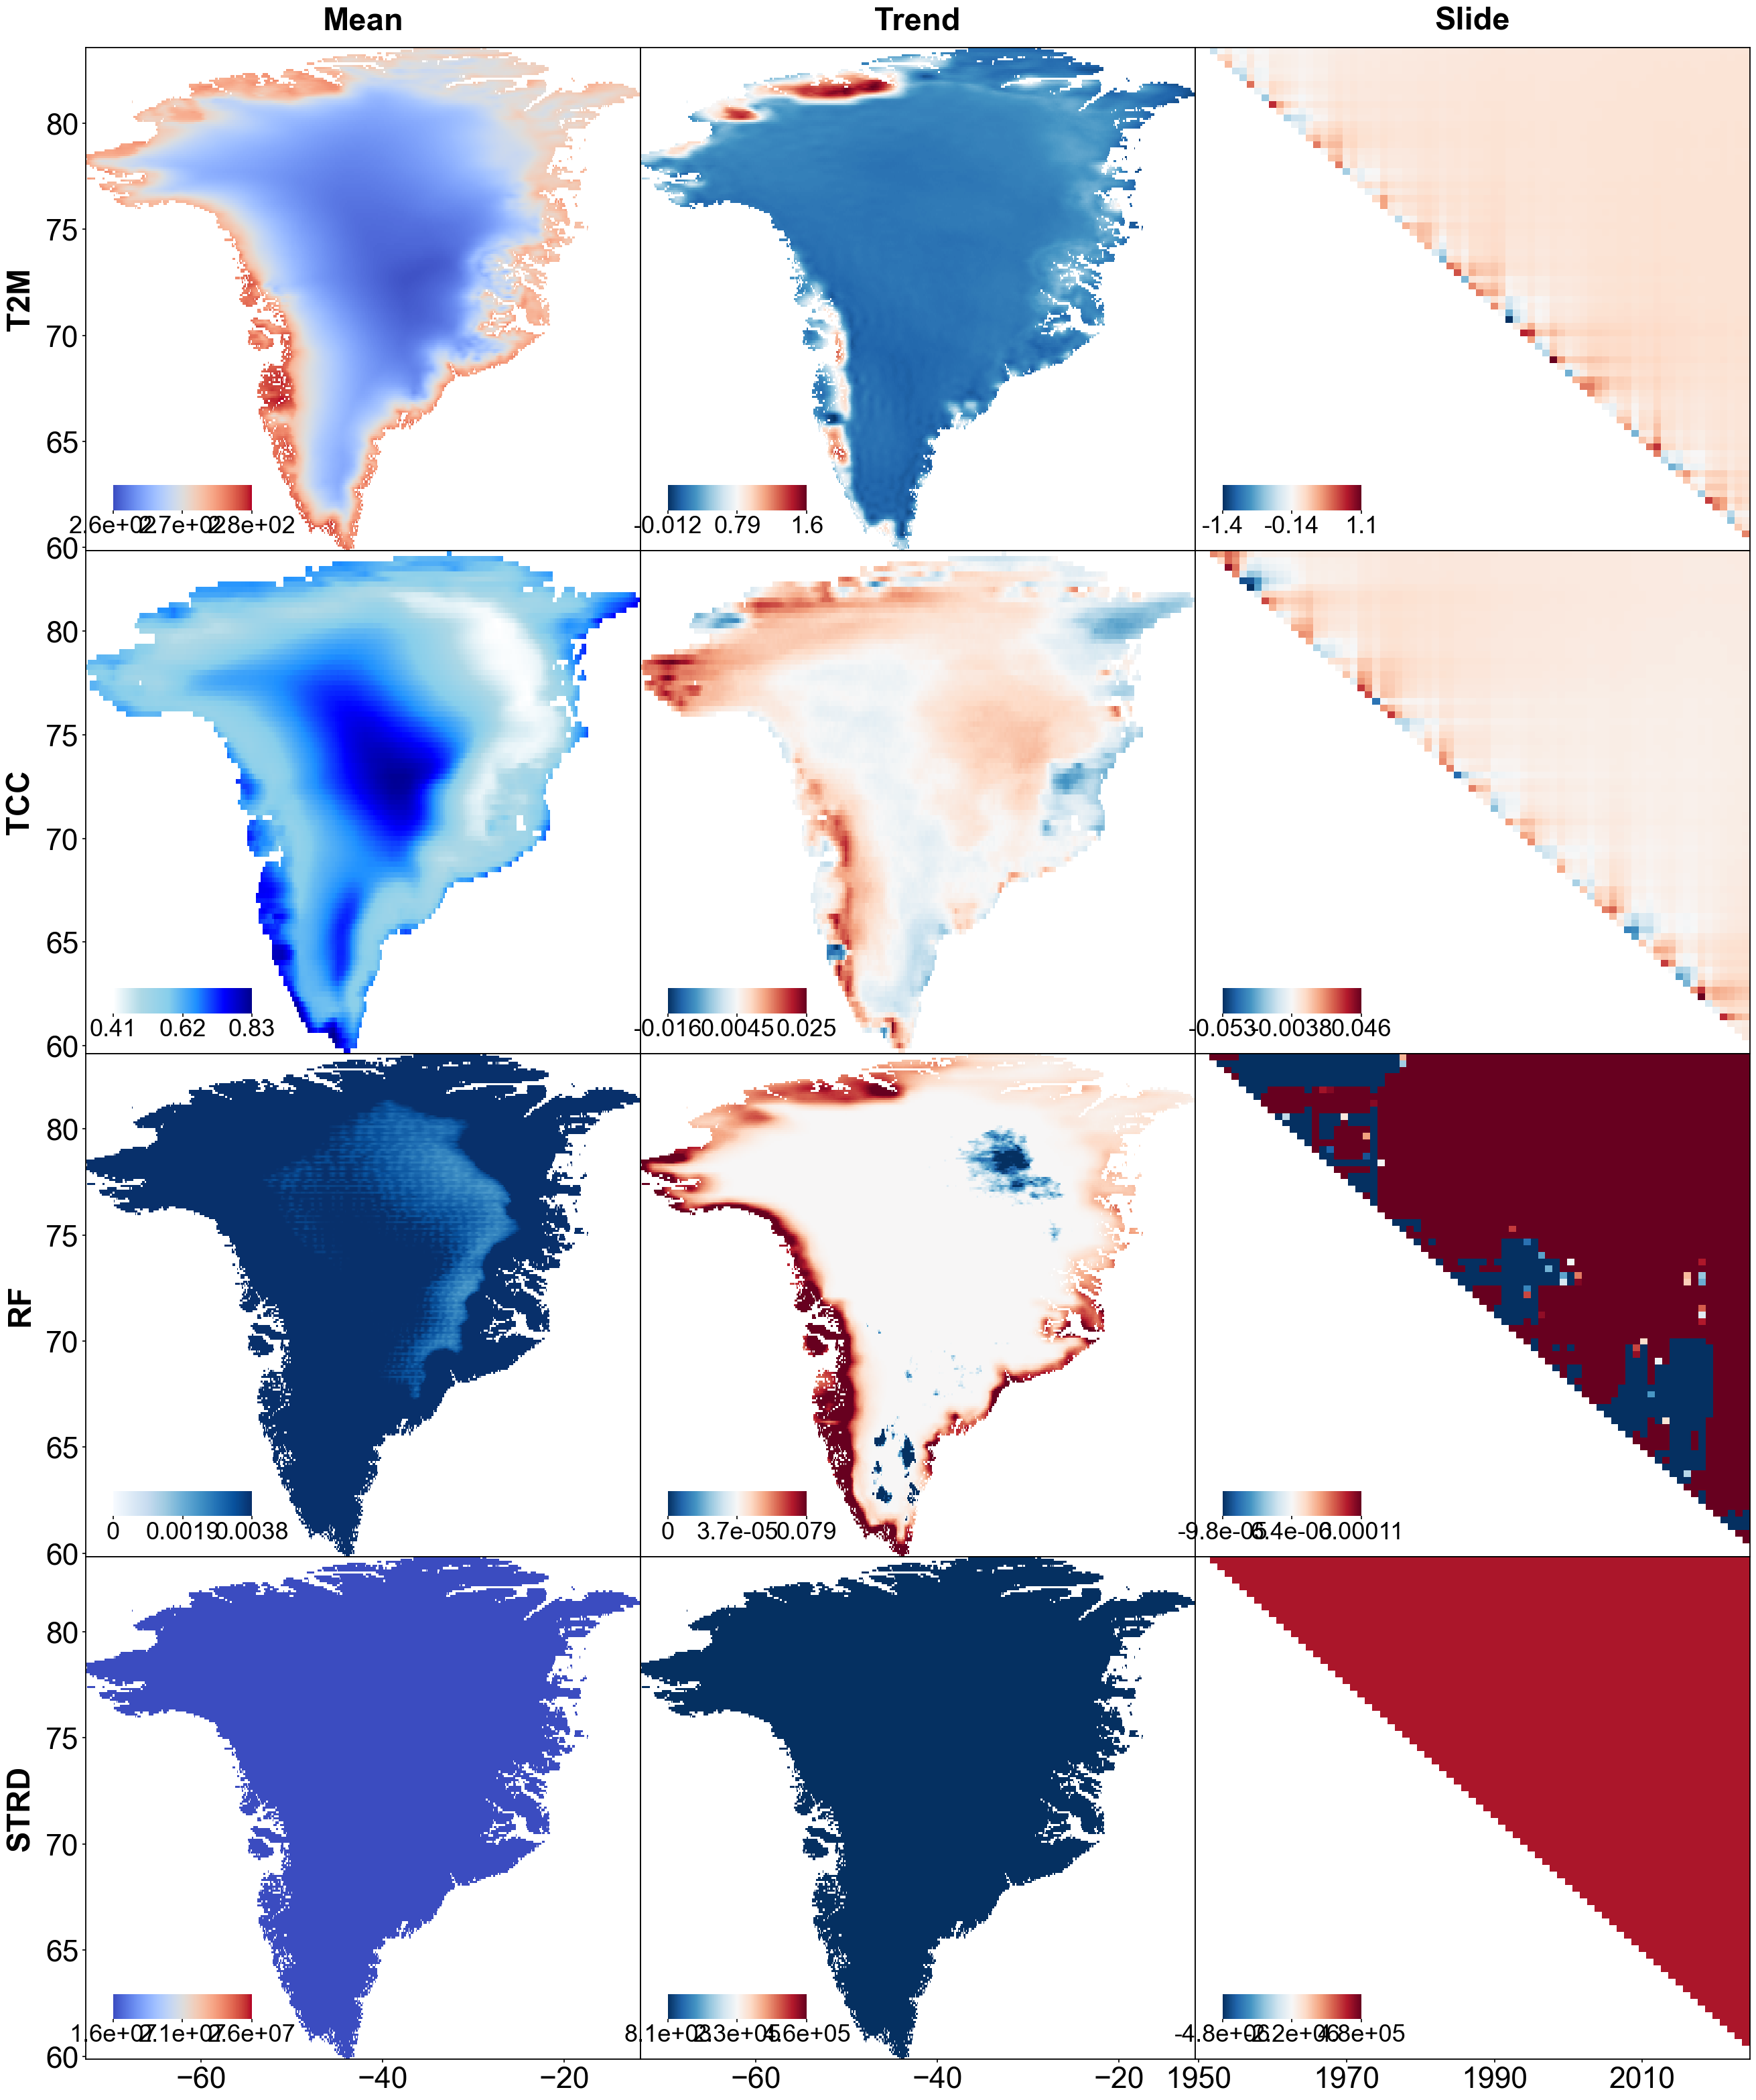

In [30]:
# -*- coding: utf-8 -*-
"""
Final 4×3 Greenland Climate Panel
(Fully robust vmin-vcenter-vmax handling; RF+STRD fixed; 2-decimal colorbars)
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0
WSPACE = 0
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_4x3panel_RF_STRD_fixed.png")
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ========== 加载色标配置 ==========
colorbar_config_path = os.path.join(DATA_DIR, "MeanTrendSlide.xlsx")
colorbar_df = pd.read_excel(colorbar_config_path)

colorbar_dict = {}
for _, row in colorbar_df.iterrows():
    try:
        feature = str(row['feature']).strip().lower()
        type_val = str(row['Type']).strip().lower()
        vmin = float(row['Min'])
        vmid = float(row['Mid'])
        vmax = float(row['Max'])
        colorbar_dict[(feature, type_val)] = (vmin, vmid, vmax)
    except Exception as e:
        print(f"⚠️ Error parsing row: {e}")
        continue

print(f"✅ Colorbar config loaded: {len(colorbar_dict)} entries")

# ========== 加载等高线 ==========
contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(27, 33))
VARS = ["t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]
n_rows, n_cols = len(VARS), len(COL_NAMES)

left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

# ========== 工具函数 ==========
def ensure_ascending(vmin, vmid, vmax, eps_ratio=1e-6):
    """确保vmin < vmid < vmax，必要时自动修复"""
    vals = [vmin, vmid, vmax]
    vals = [float(v) for v in vals]
    # 排序修正
    if not (vals[0] < vals[1] < vals[2]):
        vals = sorted(vals)
    # 若相等则微扰
    eps = max(abs(vals[2] - vals[0]), 1e-12) * eps_ratio
    if vals[0] >= vals[1]:
        vals[1] = vals[0] + eps
    if vals[1] >= vals[2]:
        vals[2] = vals[1] + eps
    return vals

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)

        # ===== 读取色标配置并修正 =====
        col_type = col.lower()
        key = (var, col_type)
        if key in colorbar_dict:
            vmin, vmid, vmax = colorbar_dict[key]
        else:
            # 备用自动范围
            arr = mean_grid.values if col=="Mean" else trend_grid.values if col=="Trend" else vals_masked
            vmin, vmax = np.nanmin(arr), np.nanmax(arr)
            vmid = (vmin + vmax) / 2

        vmin, vmid, vmax = ensure_ascending(vmin, vmid, vmax)

        # ===== RF特殊防饱和处理 =====
        if var == "rf":
            mean_grid *= 1e3
            trend_grid *= 1e3
            vals_masked *= 1e3
            if col == "Trend":
                vmin = np.nanpercentile(trend_grid.values, 5)
                vmax = np.nanpercentile(trend_grid.values, 95)
                vmid = 0
                vmin, vmid, vmax = ensure_ascending(vmin, vmid, vmax)

        # ===== STRD单位修正 =====
        if var == "strd":
            trend_grid = trend_grid / 1e5
            mean_grid = mean_grid / 1e7
            vals_masked = vals_masked / 1e6
            vmin, vmid, vmax = ensure_ascending(vmin, vmid, vmax)

        # ===== 绘图 =====
        cmap = "RdBu_r" if col != "Mean" else "coolwarm"
        if var == "tcc" and col == "Mean":
            cmap = LinearSegmentedColormap.from_list('cloud', ['white','lightblue','skyblue','dodgerblue','blue','darkblue'])
        if var == "rf" and col == "Mean":
            cmap = "Blues"

        norm = (TwoSlopeNorm(vmin=vmin, vcenter=vmid, vmax=vmax)
                if col != "Mean" else Normalize(vmin=vmin, vmax=vmax))

        data = mean_grid if col=="Mean" else trend_grid if col=="Trend" else vals_masked
        x = lons if col != "Slide" else years
        y = lats if col != "Slide" else slide_years
        im = ax.pcolormesh(x, y, data.values if hasattr(data, 'values') else data,
                           cmap=cmap, norm=norm, shading="auto")

        if col == "Slide":
            ax.invert_yaxis()

        # ===== colorbar在左下角 =====
        cb_ax = inset_axes(ax, width="25%", height="5%", loc='lower left',
                           bbox_to_anchor=(0.05, 0.08, 1, 1),
                           bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax, orientation='horizontal')
        cb.outline.set_visible(False)
        cb.set_ticks([vmin, vmid, vmax])
        cb.set_ticklabels([f"{vmin:.2g}", f"{vmid:.2g}", f"{vmax:.2g}"])
        cb.ax.tick_params(labelsize=FONT_SIZE-6, pad=2)

        # ===== 样式 =====
        if i < n_rows - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=20)
        if j == 0:
            ax.text(-0.09, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=FONT_SIZE)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()
